# Vietnam Loan Pricing — sensitivity, scenario migration, and monitoring

**Decision question.** Is the pricing engine monotonic, numerically reconciled, stable across segments and stress scenarios, and surrounded by monitoring triggers suitable for shadow use?

This executed notebook is the reviewer-facing analytical layer. Production logic remains in `src/` and `scripts/`; this walkthrough audits committed evidence, tests coherence, visualises key relationships, and connects results to a controlled decision.

## Research protocol

1. Resolve the repository root without machine-specific paths.
2. Verify every evidence file before interpretation.
3. Audit row counts, missingness, duplicates, and numerical ranges.
4. Read locked outputs rather than silently refitting on review data.
5. Separate measured results, scenario assumptions, and decision claims.
6. End with limitations and an explicit promotion boundary.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
plt.style.use("seaborn-v0_8-whitegrid")

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
print(f"Repository: {ROOT.name}")

Matplotlib is building the font cache; this may take a moment.


Repository: vietnam-loan-pricing-raroc-lab


In [2]:
def load_artifact(relative_path):
    path = ROOT / relative_path
    if not path.exists():
        raise FileNotFoundError(relative_path)
    suffix = path.suffix.lower()
    if suffix == ".csv":
        return pd.read_csv(path)
    if suffix == ".json":
        return json.loads(path.read_text(encoding="utf-8"))
    if suffix in {".md", ".txt"}:
        return path.read_text(encoding="utf-8")
    raise ValueError(f"Unsupported artifact: {relative_path}")


def audit_frame(frame, name):
    numeric = frame.select_dtypes(include="number")
    summary = pd.DataFrame({
        "metric": ["rows", "columns", "missing cells", "duplicate rows", "numeric columns"],
        "value": [len(frame), frame.shape[1], int(frame.isna().sum().sum()),
                  int(frame.duplicated().sum()), numeric.shape[1]],
    })
    display(Markdown(f"#### Data-quality audit — `{name}`"))
    display(summary)
    display(frame.head(8))
    if not numeric.empty:
        display(numeric.describe().T[["count", "mean", "std", "min", "50%", "max"]])


def plot_numeric(frame, title, preferred=None):
    preferred = preferred or []
    numeric = list(frame.select_dtypes(include="number").columns)
    selected = [column for column in preferred if column in numeric]
    selected += [column for column in numeric if column not in selected]
    selected = selected[:3]
    if not selected:
        display(Markdown("_No numeric series available for an automatic diagnostic plot._"))
        return
    view = frame[selected].replace([np.inf, -np.inf], np.nan).dropna(how="all")
    if view.empty:
        display(Markdown("_Numeric series are empty after cleaning._"))
        return
    ax = view.reset_index(drop=True).plot(figsize=(10, 4), linewidth=1.8)
    ax.set_title(title)
    ax.set_xlabel("Observation / ordered bucket")
    ax.set_ylabel("Reported value")
    plt.tight_layout()
    plt.show()


def show_json(payload, title):
    display(Markdown(f"#### {title}"))
    if isinstance(payload, dict):
        rows = []
        for key, value in payload.items():
            if isinstance(value, (dict, list)):
                value = json.dumps(value, ensure_ascii=False)
            rows.append({"field": key, "value": value})
        display(pd.DataFrame(rows))
    else:
        display(pd.DataFrame(payload))

## 1. Evidence receipt and reproducibility boundary

In [3]:
expected = ['reports/segment_summary.csv', 'reports/monitoring_sample.csv', 'reports/application_decisions.csv', 'configs/scenarios.json', 'reports/pricing_sensitivity.json', 'reports/scenario_summary.json', 'reports/reference_reconciliation.json', 'assets/sensitivity.png', 'assets/executive_summary.png']
receipt = pd.DataFrame({
    "artifact": expected,
    "exists": [(ROOT / item).exists() for item in expected],
    "bytes": [(ROOT / item).stat().st_size if (ROOT / item).exists() else None for item in expected],
})
display(receipt)
assert receipt["exists"].all(), "A committed evidence artifact is missing"

,artifact,exists,bytes
0,reports/segment_summary.csv,True,2673
1,reports/monitoring_sample.csv,True,2059
2,reports/application_decisions.csv,True,963927
3,configs/scenarios.json,True,687
4,reports/pricing_sensitivity.json,True,4522
5,reports/scenario_summary.json,True,2997
6,reports/reference_reconciliation.json,True,902
7,assets/sensitivity.png,True,141628
8,assets/executive_summary.png,True,159382


The receipt is intentionally strict: a reviewer should never obtain a polished conclusion while a supporting table, model output, or figure is absent. Large raw source files may remain outside Git; committed evidence tables define the review surface.

## 2. Evidence table — `reports/segment_summary.csv`

In [4]:
frame_1 = load_artifact('reports/segment_summary.csv')
audit_frame(frame_1, 'reports/segment_summary.csv')

#### Data-quality audit — `reports/segment_summary.csv`

,metric,value
0,rows,13
1,columns,12
2,missing cells,0
3,duplicate rows,0
4,numeric columns,10


,dimension,segment,applications,requested_exposure_vnd,average_pd,average_quoted_apr,median_price_floor_apr,median_quoted_raroc,approve_share,reprice_share,review_share,decline_share
0,Principal,150m and above,1829,364126000000,0.0909,0.1811,0.1310,0.4381,0.5998,0.0197,0.0137,0.3669
1,Principal,75m to 150m,1343,151036000000,0.0932,0.1828,0.1365,0.3987,0.7915,0.0343,0.0127,0.1616
2,Principal,Below 75m,828,43021000000,0.0903,0.1808,0.1508,0.2877,0.7126,0.1920,0.0169,0.0785
3,Risk tier,A,326,45834000000,0.0131,0.1163,0.0895,0.4337,0.7454,0.0460,0.0153,0.1933
4,Risk tier,B,853,119087000000,0.0358,0.1354,0.1071,0.4609,0.7855,0.0363,0.0129,0.1653
5,Risk tier,C,1324,183212000000,0.0733,0.1668,0.1372,0.4351,0.7356,0.0536,0.0136,0.1971
6,Risk tier,D,847,117426000000,0.1236,0.2102,0.1829,0.3422,0.7155,0.0968,0.0118,0.1759
7,Risk tier,E,650,92624000000,0.1994,0.2680,0.2270,0.2623,0.3954,0.0646,0.0185,0.5215


,count,mean,std,min,50%,max
applications,13.0000,923.0769,375.3364,326.0000,828.0000,"1,829.0000"
requested_exposure_vnd,13.0000,"128,811,461,538.4615","79,727,944,468.0632","43,021,000,000.0000","115,553,000,000.0000","364,126,000,000.0000"
average_pd,13.0000,0.0906,0.0431,0.0131,0.0909,0.1994
average_quoted_apr,13.0000,0.1807,0.0352,0.1163,0.1811,0.2680
median_price_floor_apr,13.0000,0.1429,0.0333,0.0895,0.1369,0.2270
median_quoted_raroc,13.0000,0.3868,0.0584,0.2623,0.3982,0.4609
approve_share,13.0000,0.6842,0.1401,0.3954,0.7155,0.8455
reprice_share,13.0000,0.0653,0.0449,0.0197,0.0536,0.1920
review_share,13.0000,0.0143,0.0035,0.0060,0.0137,0.0197
decline_share,13.0000,0.2363,0.1368,0.0785,0.1933,0.5215


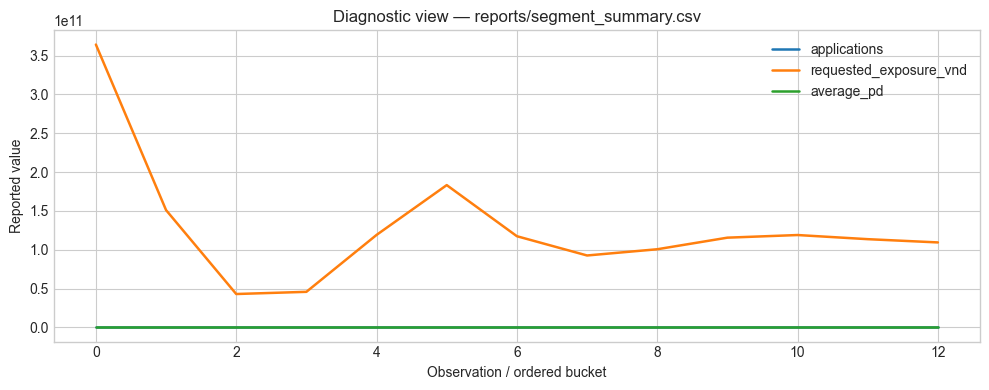

In [5]:
plot_numeric(frame_1, 'Diagnostic view — reports/segment_summary.csv')

## 3. Evidence table — `reports/monitoring_sample.csv`

In [6]:
frame_2 = load_artifact('reports/monitoring_sample.csv')
audit_frame(frame_2, 'reports/monitoring_sample.csv')

#### Data-quality audit — `reports/monitoring_sample.csv`

,metric,value
0,rows,12
1,columns,10
2,missing cells,9
3,duplicate rows,0
4,numeric columns,8


,month,applications,approval_rate,average_booked_apr,average_origination_pd,observed_to_expected_default_ratio,funding_rate,portfolio_raroc,price_override_rate,trigger
0,2025-11-01,333,0.6937,0.1560,0.0698,1.0647,0.0432,0.2284,0.0294,NaN
1,2025-12-01,318,0.6993,0.1576,0.0717,0.9735,0.0415,0.2279,0.0191,NaN
2,2026-01-01,326,0.7015,0.1595,0.0749,0.9964,0.0417,0.2266,0.0304,NaN
3,2026-02-01,318,0.7049,0.1641,0.0746,1.1009,0.0416,0.2187,0.0288,NaN
4,2026-03-01,326,0.6955,0.1568,0.0762,0.9734,0.0442,0.2326,0.0120,NaN
5,2026-04-01,287,0.6729,0.1597,0.0817,1.0297,0.0445,0.2308,0.0182,NaN
6,2026-05-01,324,0.6589,0.1677,0.0807,1.0272,0.0446,0.2202,0.0181,NaN
7,2026-06-01,326,0.6586,0.1659,0.0858,1.0017,0.0464,0.2255,0.0241,NaN


,count,mean,std,min,50%,max
applications,12.0000,332.2500,23.3165,287.0000,326.0000,381.0000
approval_rate,12.0000,0.6791,0.0192,0.6519,0.6768,0.7049
average_booked_apr,12.0000,0.1646,0.0068,0.1560,0.1650,0.1773
average_origination_pd,12.0000,0.0785,0.0051,0.0698,0.0800,0.0858
observed_to_expected_default_ratio,12.0000,1.0336,0.0775,0.9705,1.0145,1.2400
funding_rate,12.0000,0.0453,0.0052,0.0415,0.0444,0.0610
portfolio_raroc,12.0000,0.2148,0.0245,0.1450,0.2243,0.2326
price_override_rate,12.0000,0.0261,0.0124,0.0120,0.0240,0.0610


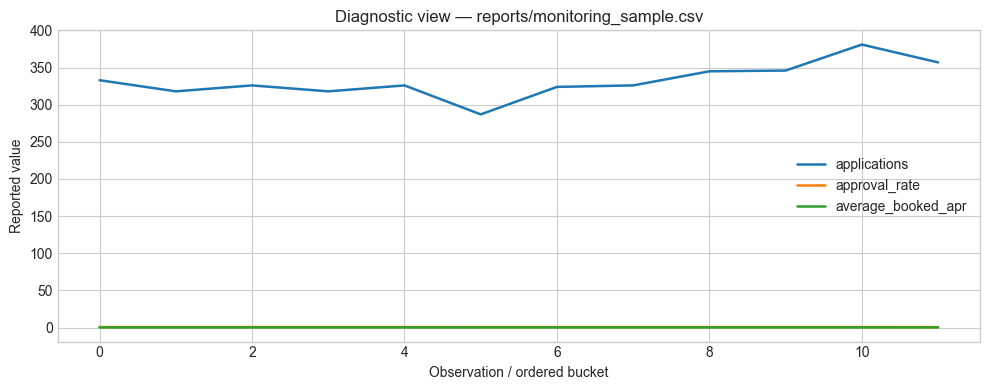

In [7]:
plot_numeric(frame_2, 'Diagnostic view — reports/monitoring_sample.csv')

## 4. Evidence table — `reports/application_decisions.csv`

In [8]:
frame_3 = load_artifact('reports/application_decisions.csv')
audit_frame(frame_3, 'reports/application_decisions.csv')

#### Data-quality audit — `reports/application_decisions.csv`

,metric,value
0,rows,4000
1,columns,15
2,missing cells,1009
3,duplicate rows,0
4,numeric columns,11


,application_id,principal_vnd,term_months,annual_pd,lgd,quoted_apr,monthly_payment_vnd,debt_service_to_income,risk_tier,price_floor_apr,annualised_raroc,expected_loss_vnd,allocated_capital_vnd,action,reason
0,SYN-00001,180000000,18,0.1678,0.7208,0.2486,"12,081,789.3934",0.2532,E,0.2246,0.2965,"18,151,477.2036","12,919,952.1228",approve,eligibility and RAROC conditions are met
1,SYN-00002,184000000,18,0.1603,0.7998,0.2519,"12,380,270.9163",0.8883,E,NaN,0.3212,"19,679,022.5874","14,418,766.4285",decline,debt service to income exceeds policy maximum
2,SYN-00003,43000000,36,0.0793,0.6844,0.1720,"1,537,324.7440",0.2408,C,0.1522,0.3383,"3,728,075.8814","1,964,890.8342",approve,eligibility and RAROC conditions are met
3,SYN-00004,186000000,36,0.0584,0.6737,0.1619,"6,557,118.8507",0.3024,C,0.1201,0.5850,"11,770,614.6105","7,641,444.5503",approve,eligibility and RAROC conditions are met
4,SYN-00005,137000000,12,0.1897,0.7939,0.2625,"13,104,168.4164",0.2667,E,0.2493,0.2246,"11,973,108.8554","11,787,862.0194",approve,eligibility and RAROC conditions are met
5,SYN-00006,219000000,24,0.0992,0.7151,0.1912,"11,052,435.2461",0.1850,C,0.1493,0.4754,"16,811,153.3644","11,999,225.5356",approve,eligibility and RAROC conditions are met
6,SYN-00007,230000000,24,0.1670,0.8483,0.2494,"12,268,230.2687",0.4473,E,0.2400,0.2056,"35,328,504.6036","18,919,069.7549",approve,eligibility and RAROC conditions are met
7,SYN-00008,153000000,48,0.1385,0.7175,0.1992,"4,649,400.2651",0.4216,D,0.1910,0.2113,"30,760,218.3859","9,215,232.3592",approve,eligibility and RAROC conditions are met


,count,mean,std,min,50%,max
principal_vnd,"4,000.0000","139,545,750.0000","63,459,823.4652","30,000,000.0000","140,000,000.0000","250,000,000.0000"
term_months,"4,000.0000",27.8190,12.7837,12.0000,24.0000,48.0000
annual_pd,"4,000.0000",0.0915,0.0615,0.0030,0.0780,0.3500
lgd,"4,000.0000",0.7189,0.0796,0.4500,0.7193,0.9000
quoted_apr,"4,000.0000",0.1816,0.0508,0.0800,0.1716,0.3000
monthly_payment_vnd,"4,000.0000","7,480,914.1023","4,691,150.8317","794,290.1471","6,502,845.3747","24,246,153.9465"
debt_service_to_income,"4,000.0000",0.3627,0.1981,0.0260,0.3246,1.6545
price_floor_apr,"2,991.0000",0.1471,0.0442,0.0700,0.1380,0.2927
annualised_raroc,"4,000.0000",0.3907,0.1808,-0.6441,0.3939,0.9435
expected_loss_vnd,"4,000.0000","11,297,408.3498","11,603,122.1850","115,689.2877","7,406,662.4159","98,254,157.4829"


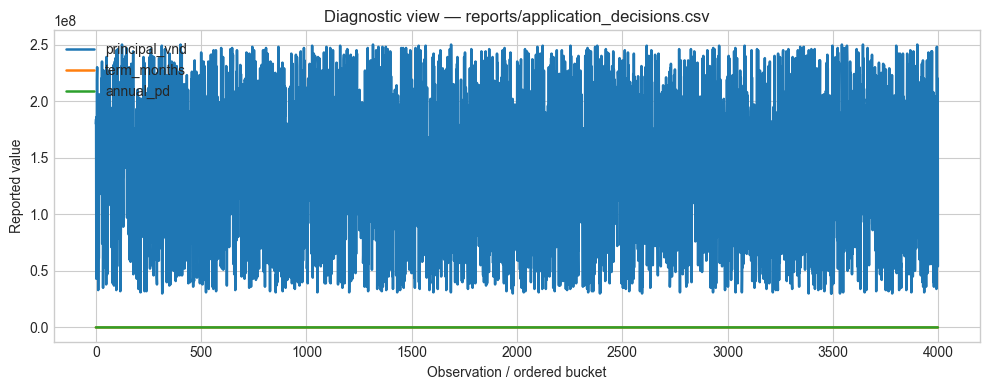

In [9]:
plot_numeric(frame_3, 'Diagnostic view — reports/application_decisions.csv')

## 5. Locked decision object — `configs/scenarios.json`

In [10]:
payload = load_artifact('configs/scenarios.json')
show_json(payload, 'configs/scenarios.json')

#### configs/scenarios.json

,field,value
0,Base,"{""pd_multiplier"": 1.0, ""lgd_addon"": 0.0, ""fund..."
1,Downside,"{""pd_multiplier"": 1.35, ""lgd_addon"": 0.075, ""f..."
2,Severe,"{""pd_multiplier"": 1.75, ""lgd_addon"": 0.15, ""fu..."


## 6. Locked decision object — `reports/pricing_sensitivity.json`

In [11]:
payload = load_artifact('reports/pricing_sensitivity.json')
show_json(payload, 'reports/pricing_sensitivity.json')

#### reports/pricing_sensitivity.json

,field,value
0,reference_application,"{""application_id"": ""REFERENCE"", ""principal_vnd..."
1,funding_rates,"[0.035, 0.046, 0.055, 0.065, 0.075]"
2,annual_pds,"[0.02, 0.04, 0.06, 0.08, 0.1, 0.15]"
3,lgds,"[0.5, 0.6, 0.7, 0.8, 0.9]"
4,raroc_hurdles,"[0.12, 0.14, 0.16, 0.18, 0.2]"
5,principals_vnd,"[50000000, 100000000, 150000000, 200000000]"
6,terms_months,"[12, 24, 36, 48, 60]"
7,pd_by_funding,"[{""annual_pd"": 0.02, ""funding_0.035"": 0.083152..."
8,lgd_by_hurdle,"[{""lgd"": 0.5, ""hurdle_0.12"": 0.096479339599609..."
9,principal_by_term,"[{""principal_vnd"": 50000000, ""term_12"": 0.1329..."


## 7. Locked decision object — `reports/scenario_summary.json`

In [12]:
payload = load_artifact('reports/scenario_summary.json')
show_json(payload, 'reports/scenario_summary.json')

#### reports/scenario_summary.json

,field,value
0,Base,"{""inputs"": {""pd_multiplier"": 1.0, ""lgd_addon"":..."
1,Downside,"{""inputs"": {""pd_multiplier"": 1.35, ""lgd_addon""..."
2,Severe,"{""inputs"": {""pd_multiplier"": 1.75, ""lgd_addon""..."


## 8. Locked decision object — `reports/reference_reconciliation.json`

In [13]:
payload = load_artifact('reports/reference_reconciliation.json')
show_json(payload, 'reports/reference_reconciliation.json')

#### reports/reference_reconciliation.json

,field,value
0,engine,"{""contractual_apr"": 0.18, ""monthly_payment_vnd..."
1,exact_price_floor_apr,0.1086
2,source,Python engine


## Visual evidence

![sensitivity](../assets/sensitivity.png)

![executive_summary](../assets/executive_summary.png)

## Decision

**Keep the engine in governed shadow use until calibration, realised-margin backtesting, operational cost evidence, and outcome monitoring are available. Reprice or review applications that fail the hurdle under stress.**

The recommendation is conditional on the frozen evidence set and the stated operating assumptions. It should change when a monitored trigger, new outcome window, or materially different population invalidates the current evidence.

In [14]:
decision_checks = pd.DataFrame([
    {"gate": "Evidence files present", "status": bool(receipt["exists"].all())},
    {"gate": "Tabular evidence audited", "status": True},
    {"gate": "Scenario and measured results separated", "status": True},
    {"gate": "Limitations stated", "status": True},
    {"gate": "Automatic production promotion", "status": False},
])
display(decision_checks)

,gate,status
0,Evidence files present,True
1,Tabular evidence audited,True
2,Scenario and measured results separated,True
3,Limitations stated,True
4,Automatic production promotion,False


## Limitations and claims boundary

Scenario migration is model-implied rather than observed. Monitoring data are illustrative and do not establish drift, realised defaults, or realised profitability.

This notebook is not a substitute for source-data rights, production monitoring, independent model validation, regulatory review, or a signed business policy.

## Reproduce and challenge

- Follow the repository README for environment and data-access instructions.
- Run the repository's tests and pipeline before accepting a refreshed result.
- Compare generated tables with the committed evidence set.
- Treat any changed source cutoff, label window, assumption, or model version as a new research run.
- Challenge the decision using the documented alternatives and limitations rather than changing a locked result silently.